# Uplix Live: train, duel, and publish to the dashboard

This notebook does the model work for the project. It runs in a few minutes on a laptop.

1. **Loads** participants from the database (synthetic now, real later). The synthetic data has *exactly* the same tables as the real shop.
2. **Trains two ways of choosing who gets a coupon:** *traditional* (likeliest buyers) and *uplift* (biggest change caused by the coupon), at the same budget.
3. **Checks honesty:** repeats over 10 random crowds, and in a world where the coupon does nothing.
4. **Publishes** the results into the `model_runs` table, which the dashboard reads.
5. **Analyses the real experiment** once real users exist (effect, exact test, interval, power).

Everything from synthetic data is **SIMULATED**. It shows the method works, not what your real users do.

In [1]:
import os, sys, re, json
from itertools import combinations
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

ROOT = "." if os.path.exists("tools") else ".."
sys.path.insert(0, ROOT)
from tools.synth import generate, features_from_frames
sys.path.insert(0, os.path.join(ROOT, "ml_service"))
from uplix_ml import engineer, to_spec        # the same feature function the FastAPI service uses

pd.set_option("display.precision", 3); pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 0
FEATURES = ["n_views_r1", "n_cart_adds_r1", "avg_price_viewed_r1", "n_orders_r1", "r1_spend"]   # Round 1 only, so no leakage
DATABASE_URL = os.environ.get("DATABASE_URL")
print("Database:", "connected via DATABASE_URL" if DATABASE_URL else "none set, so synthetic data is generated in memory")

Database: connected via DATABASE_URL


## 1. Load the data

The query reads the view `v_features`: one row per participant with the coupon group `T`, the Round 2 outcome, and Round 1 behaviour. Without a `DATABASE_URL` the notebook generates the same kind of data in memory, so it always runs.

In [2]:
seed_sql = open(os.path.join(ROOT, "sql", "seed_products.sql"), encoding="utf-8").read()
PRODUCTS = pd.DataFrame(re.findall(r"\((\d+),'([^']+)','([^']+)',(\d+)\)", seed_sql), columns=["id", "name", "category", "price"]).astype({"id": int, "price": int})

def load_features(source):
    if not DATABASE_URL:
        if source == "real":
            return pd.DataFrame()
        d = generate(PRODUCTS, n=10000, seed=SEED)
        return features_from_frames(d)
    import psycopg
    with psycopg.connect(DATABASE_URL, prepare_threshold=None) as conn:
        cur = conn.cursor()
        cur.execute('select * from v_features where source = %s', (source,))
        df = pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])
    num = [c for c in df.columns if c not in ("source",)]
    df[num] = df[num].astype(float)
    return df

syn = load_features("synthetic")
print("synthetic participants:", len(syn), "| coupon share:", syn["T"].mean().round(3))
syn.groupby("T")[["Y_order_r2", "revenue_r2", "n_views_r1", "avg_price_viewed_r1", "r1_spend"]].mean().rename(index={0: "No coupon", 1: "Coupon"})

synthetic participants: 10000 | coupon share: 0.5


,Y_order_r2,revenue_r2,n_views_r1,avg_price_viewed_r1,r1_spend
T,,,,,
No coupon,0.263,286.396,3.550,799.713,560.678
Coupon,0.264,204.458,3.623,795.194,583.293


Notice the **average** effect of the coupon is close to zero. That is by design in the simulation: persuadable people order more, sleeping dogs order less, and they cancel out. A plain average would say "the coupon does nothing". Uplift looks *inside* the average.

## 2. The duel: traditional versus uplift

- **Traditional:** a model predicts who will order in Round 2 from Round 1 behaviour (after feature engineering). It never sees who got a coupon. Coupons go to the highest predicted orderers.
- **Uplift:** two models, one fitted on coupon users and one on non-coupon users. The gap between their predictions is each person's estimated *change*. Coupons go to the biggest change.
- **Random:** the benchmark.

Rules that keep it fair: models are fitted on a training part, the budget is **chosen on a validation part**, and results are **reported on a separate test part**. Profit uses a doubly robust estimate that relies on the randomization, so it stays fair even if the models are imperfect.

In [3]:
LR = dict(C=1.0, max_iter=500)      # a plain logistic regression: simple, explainable, tiny to deploy
GRID = np.round(np.linspace(0, 1, 21), 2)
COUPONS = [50, 100, 150]          # coupon sizes the dashboard lets you switch between
Z = 1.96

def fit(X, y, seed): return LogisticRegression(**LR).fit(X, y)
def prob(model, X): return model.predict_proba(X)[:, 1]

def top_fraction(score, f):
    k = int(np.ceil(f * len(score)))
    pi = np.zeros(len(score)); pi[np.argsort(-score, kind="stable")[:k]] = 1
    return pi

def dr_scores(T, Y, mu0, mu1, e):
    return mu1 + T * (Y - mu1) / e, mu0 + (1 - T) * (Y - mu0) / (1 - e)   # u: if treated, w: if not

def value(pi, u, w, econ):
    psi = pi * ((econ["m"] - econ["d"]) * u - econ["c"]) + (1 - pi) * econ["m"] * w
    se = psi.std(ddof=1) / np.sqrt(len(psi))
    return psi.mean(), psi.mean() - Z * se, psi.mean() + Z * se

def difference(pi_a, pi_b, u, w, econ):
    x = (pi_a - pi_b) * (((econ["m"] - econ["d"]) * u - econ["c"]) - econ["m"] * w)
    se = x.std(ddof=1) / np.sqrt(len(x))
    return x.mean(), x.mean() - Z * se, x.mean() + Z * se

def qini_curve(score, T, Y):
    o = np.argsort(-score, kind="stable"); t, y = T[o], Y[o]
    nt, nc = np.cumsum(t), np.cumsum(1 - t)
    ratio = np.divide(nt, nc, out=np.zeros(len(t)), where=nc > 0)
    q = np.cumsum(y * t) - ratio * np.cumsum(y * (1 - t))
    return np.r_[0, np.arange(1, len(t) + 1) / len(t)], np.r_[0, q]

def run_duel(df, seed=SEED, truth=None):
    # df needs: T, Y_order_r2, revenue_r2, discount_r2 and FEATURES. truth (optional): Series of true tau by user_id.
    df = df.reset_index(drop=True)
    X = pd.DataFrame(engineer(df[FEATURES].to_numpy(float)))                 # feature engineering (shared with serving)
    T, Y = df["T"].to_numpy(int), df["Y_order_r2"].to_numpy(int)
    m = float(((df["revenue_r2"] + df["discount_r2"])[Y == 1]).mean())      # value of an order, from the data
    strata = T * 2 + Y
    idx = np.arange(len(df))
    train, rest = train_test_split(idx, test_size=0.4, random_state=seed, stratify=strata)
    valid, test = train_test_split(rest, test_size=0.5, random_state=seed, stratify=strata[rest])
    scaler = StandardScaler().fit(X.iloc[train]); X = pd.DataFrame(scaler.transform(X))   # fitted on TRAIN only
    e = T.mean()
    traditional = fit(X.iloc[train], Y[train], seed)                          # never sees T
    m0 = fit(X.iloc[train][T[train] == 0], Y[train][T[train] == 0], seed)     # uplift: two models
    m1 = fit(X.iloc[train][T[train] == 1], Y[train][T[train] == 1], seed)

    def part(ix):
        Xi = X.iloc[ix]; mu0, mu1 = prob(m0, Xi), prob(m1, Xi)
        u, w = dr_scores(T[ix], Y[ix], mu0, mu1, e)
        return dict(p_buy=prob(traditional, Xi), tau=mu1 - mu0, u=u, w=w, T=T[ix], Y=Y[ix])
    V, S = part(valid), part(test)

    def evaluate(d):
        econ = dict(m=m, d=d, c=0.0)
        f_star = GRID[int(np.argmax([value(top_fraction(V["tau"], f), V["u"], V["w"], econ)[0] for f in GRID]))]   # chosen on VALIDATION
        pol = {"Never treat": 0.0, "Treat everyone": 1.0, "Random (same budget)": f_star,
               "Traditional: likeliest buyers": top_fraction(S["p_buy"], f_star),
               "Uplift: biggest change": top_fraction(S["tau"], f_star)}
        table = {k: value(p, S["u"], S["w"], econ) for k, p in pol.items()}
        up = pol["Uplift: biggest change"]
        diffs = {"Uplift minus never": difference(up, 0.0, S["u"], S["w"], econ),
                 "Uplift minus everyone": difference(up, 1.0, S["u"], S["w"], econ),
                 "Uplift minus random": difference(up, f_star, S["u"], S["w"], econ),
                 "Uplift minus traditional": difference(up, pol["Traditional: likeliest buyers"], S["u"], S["w"], econ)}
        curves = {name: [value(top_fraction(score, f) if score is not None else f, S["u"], S["w"], econ) for f in GRID]
                  for name, score in [("uplift", S["tau"]), ("traditional", S["p_buy"]), ("random", None)]}
        return dict(f_star=float(f_star), table=table, diffs=diffs, curves=curves,
                    verdict="reliable" if all(diffs[k][1] > 0 for k in ["Uplift minus never", "Uplift minus everyone", "Uplift minus random"]) else "inconclusive",
                    beats_traditional=bool(diffs["Uplift minus traditional"][1] > 0))
    by_coupon = {d: evaluate(d) for d in COUPONS}
    out = dict(m=m, by_coupon=by_coupon, n=len(df), n_test=len(test), S=S, V=V, test_idx=test,
               models=dict(scaler=scaler, traditional=traditional, control=m0, treated=m1))
    # observed uplift by model-score quintile on the test part (does the ranking really separate people?)
    q = pd.qcut(pd.Series(S["tau"]).rank(method="first", ascending=False), 5, labels=False)
    rows = []
    for k in range(5):
        s = q.to_numpy() == k; t, y = S["T"][s], S["Y"][s]
        up = y[t == 1].mean() - y[t == 0].mean()
        se = np.sqrt(y[t == 1].var(ddof=1) / max(t.sum(), 2) + y[t == 0].var(ddof=1) / max((1 - t).sum(), 2))
        rows.append(dict(group=k + 1, n=int(s.sum()), rate_coupon=float(y[t == 1].mean()), rate_no_coupon=float(y[t == 0].mean()), uplift=float(up), lo=float(up - Z * se), hi=float(up + Z * se)))
    out["quintiles"] = rows
    out["qini"] = {"uplift": qini_curve(S["tau"], S["T"], S["Y"]), "traditional": qini_curve(S["p_buy"], S["T"], S["Y"])}
    if truth is not None:
        tt = truth.reindex(df["user_id"].iloc[test]).to_numpy()
        out["truth_corr"] = float(np.corrcoef(S["tau"], tt)[0, 1])
    return out

In [4]:
truth_path = os.path.join(ROOT, "data", "synthetic_truth.csv")
truth = pd.read_csv(truth_path).set_index("user_id")["tau"] if (DATABASE_URL and os.path.exists(truth_path)) else None
main = run_duel(syn, SEED, truth)
r = main["by_coupon"][100]
print(f"Order value m (from the data): {main['m']:.0f} | coupon: 100 | budget chosen on validation: treat the top {r['f_star']:.0%}")
display(pd.DataFrame(r["table"], index=["profit per customer", "low", "high"]).T)
display(pd.DataFrame(r["diffs"], index=["difference", "low", "high"]).T)
print("Verdict:", r["verdict"], "| uplift clearly beats traditional:", r["beats_traditional"])
if "truth_corr" in main: print("Correlation of the model's uplift with the hidden truth (synthetic only):", round(main["truth_corr"], 3))

Order value m (from the data): 980 | coupon: 100 | budget chosen on validation: treat the top 25%


,profit per customer,low,high
Never treat,261.456,235.147,287.765
Treat everyone,234.037,210.416,257.658
Random (same budget),254.601,234.003,275.199
Traditional: likeliest buyers,232.980,207.901,258.059
Uplift: biggest change,303.846,276.643,331.049


,difference,low,high
Uplift minus never,42.390,24.488,60.291
Uplift minus everyone,69.809,39.513,100.105
Uplift minus random,49.245,33.899,64.590
Uplift minus traditional,70.866,47.464,94.268


Verdict: reliable | uplift clearly beats traditional: True
Correlation of the model's uplift with the hidden truth (synthetic only): 0.639


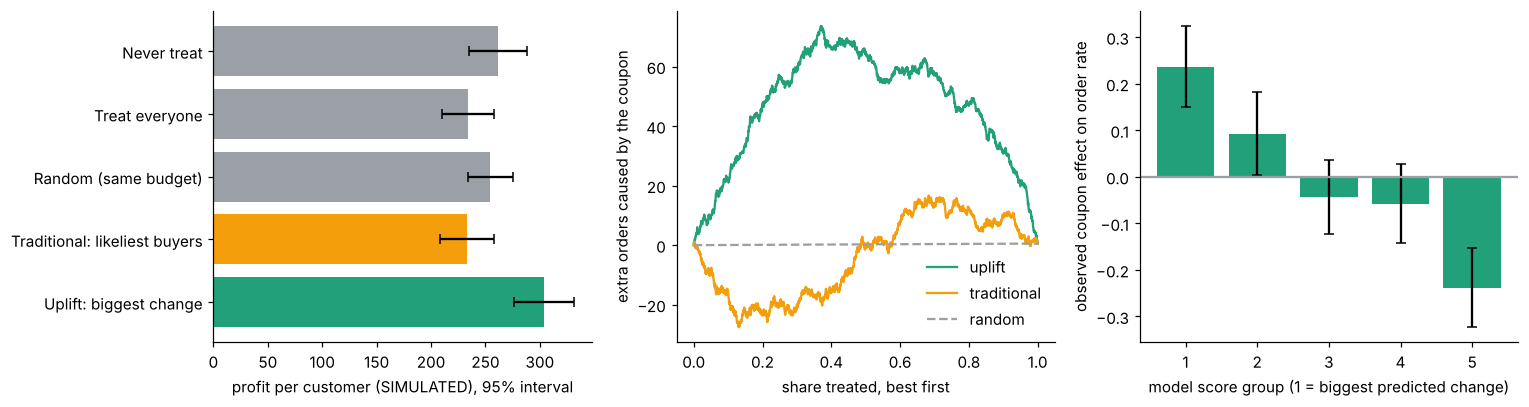

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
t = pd.DataFrame(r["table"], index=["v", "lo", "hi"]).T
ax[0].barh(t.index, t["v"], xerr=[t["v"] - t["lo"], t["hi"] - t["v"]], capsize=3,
           color=["#9aa0a6", "#9aa0a6", "#9aa0a6", "#f59e0b", "#22a07a"])
ax[0].invert_yaxis(); ax[0].set_xlabel("profit per customer (SIMULATED), 95% interval")
for name, (x, q) in main["qini"].items():
    ax[1].plot(x, q, label=name, color="#22a07a" if name == "uplift" else "#f59e0b")
ax[1].plot([0, 1], [0, main["qini"]["uplift"][1][-1]], "--", color="#9aa0a6", label="random")
ax[1].set_xlabel("share treated, best first"); ax[1].set_ylabel("extra orders caused by the coupon"); ax[1].legend(frameon=False)
qd = pd.DataFrame(main["quintiles"])
ax[2].bar(qd["group"], qd["uplift"], yerr=[qd["uplift"] - qd["lo"], qd["hi"] - qd["uplift"]], capsize=3, color="#22a07a")
ax[2].axhline(0, color="#9aa0a6"); ax[2].set_xlabel("model score group (1 = biggest predicted change)"); ax[2].set_ylabel("observed coupon effect on order rate")
plt.tight_layout(); plt.show()

**Reading the three pictures.** Left: profit at the same budget. Middle: the extra orders the coupon causes keep rising when we rank by *change*, but not when we rank by *likelihood to buy*. Right: the people the model ranks highest really do react to the coupon more (the observed effect falls from group 1 to group 5).

## 3. Is the duel rigged? Two checks

1. **10 random crowds.** How often does uplift beat traditional targeting?
2. **A world where the coupon does nothing for anyone.** Uplift has nothing to find, so an honest system must say **inconclusive**.

These use freshly generated crowds (the same generator that fills the database).

In [6]:
rows = []
for world, effect in [("Coupon effect differs by person", "heterogeneous"), ("Coupon does nothing", "none")]:
    for s in range(10):
        d = generate(PRODUCTS, n=10000, seed=100 + s, effect=effect)
        res = run_duel(features_from_frames(d), seed=s)["by_coupon"][100]
        rows.append(dict(world=world, seed=s, verdict=res["verdict"], beats_traditional=res["beats_traditional"]))
runs = pd.DataFrame(rows)
robust = runs.groupby("world").agg(reliable=("verdict", lambda v: int((v == "reliable").sum())),
                                   uplift_beats_traditional=("beats_traditional", "sum"))
robust.columns = ["runs saying 'reliable' (of 10)", "runs where uplift clearly beats traditional (of 10)"]
robust

,runs saying 'reliable' (of 10),runs where uplift clearly beats traditional (of 10)
world,,
Coupon does nothing,0,0
Coupon effect differs by person,10,9


## 4. Publish the results to the dashboard

This writes one row into `model_runs` (and a JSON file next to the notebook). The dashboard draws its graphs from it. Without a database the JSON file is still written.

In [7]:
def jf(x): return None if x is None else float(x)
def triple(t): return dict(value=jf(t[0]), lo=jf(t[1]), hi=jf(t[2]))

def build_payload(main, robust_runs, source="synthetic"):
    by = {}
    for d, r in main["by_coupon"].items():
        by[str(d)] = dict(
            f_star=r["f_star"], verdict=r["verdict"], beats_traditional=r["beats_traditional"],
            strategies=[dict(name=k, **triple(v)) for k, v in r["table"].items()],
            differences=[dict(name=k, **triple(v)) for k, v in r["diffs"].items()],
            budget_curve=dict(fractions=[float(f) for f in GRID],
                              **{name: dict(value=[jf(v[0]) for v in c], lo=[jf(v[1]) for v in c], hi=[jf(v[2]) for v in c]) for name, c in r["curves"].items()}))
    def thin(x, q): i = np.linspace(0, len(x) - 1, 101).astype(int); return dict(x=[jf(x[j]) for j in i], y=[jf(q[j]) for j in i])
    rb = {}
    for world, g in robust_runs.groupby("world"):
        rb[world] = dict(runs=int(len(g)), reliable=int((g["verdict"] == "reliable").sum()), uplift_beats_traditional=int(g["beats_traditional"].sum()))
    return dict(source=source, simulated=(source == "synthetic"), n=int(main["n"]), n_test=int(main["n_test"]),
                order_value=jf(main["m"]), features=FEATURES, model="Logistic regression T-learner (traditional vs two-model uplift)",
                by_coupon=by, quintiles=main["quintiles"], qini={k: thin(*v) for k, v in main["qini"].items()},
                robustness=rb, truth_corr=main.get("truth_corr"), generated_at=datetime.now(timezone.utc).isoformat())

payload = build_payload(main, runs)
os.makedirs(os.path.join(ROOT, "data"), exist_ok=True)
with open(os.path.join(ROOT, "data", "model_run_synthetic.json"), "w") as f:
    json.dump(payload, f)
if DATABASE_URL:
    import psycopg
    from psycopg.types.json import Jsonb
    with psycopg.connect(DATABASE_URL, prepare_threshold=None) as conn:
        conn.execute("insert into model_runs (source, results) values (%s, %s)", ("synthetic", Jsonb(payload)))
    print("saved a row in model_runs")
print("saved data/model_run_synthetic.json |", round(os.path.getsize(os.path.join(ROOT, "data", "model_run_synthetic.json")) / 1024), "KB")

saved a row in model_runs
saved data/model_run_synthetic.json | 21 KB


### 4b. Export the model for the FastAPI service

The model is two logistic regressions plus a scaler, so it is saved as plain numbers (a few KB). The FastAPI service loads this file and predicts with numpy only.

In [8]:
# Export the trained model for the FastAPI service: a small JSON file that needs only numpy to use.
mm = main["models"]; r100 = main["by_coupon"][100]
cutoff = float(np.quantile(main["V"]["tau"], 1 - r100["f_star"]))      # uplift score that marks the top f* of customers (from VALIDATION)
spec = to_spec(mm["scaler"], mm["traditional"], mm["control"], mm["treated"],
               economics=dict(m=float(main["m"]), d=100.0, c=0.0),
               meta=dict(source="synthetic", simulated=True, n_train=int(0.6 * main["n"]), f_star=r100["f_star"], uplift_cutoff=cutoff,
                         metrics=dict(verdict=r100["verdict"], uplift_minus_traditional=float(r100["diffs"]["Uplift minus traditional"][0]),
                                      uplift_minus_random=float(r100["diffs"]["Uplift minus random"][0]))))
path = os.path.join(ROOT, "ml_service", "model.json")
with open(path, "w") as f:
    json.dump(spec, f)
print("saved", path, "|", round(os.path.getsize(path) / 1024, 1), "KB")

saved ../ml_service/model.json | 1.7 KB


## 5. Your real experiment

Run this part after the class experiment. It needs real participants with a coupon assignment and Round 2 results (or an `export.csv` from the admin page).

- **Exact randomization test:** re-runs every possible split of the same people into two groups and counts how often a gap this large appears by chance.
- **Bootstrap interval:** a rough range for the effect. At small sizes it is *very* rough.
- **Verdict:** "reliable" only with at least 40 users, a significant exact test, and an interval that excludes zero.
- **No uplift model on real data until there are at least 200 users.** Below that a model would only memorise noise.

In [9]:
def exact_p_value(y, t, n_mc=20000, seed=SEED):
    y, t = np.asarray(y, float), np.asarray(t, int)
    n, n1 = len(y), int(t.sum()); observed = y[t == 1].mean() - y[t == 0].mean(); total = y.sum()
    if n <= 20:
        sums = np.array([y[list(c)].sum() for c in combinations(range(n), n1)])
    else:
        rng = np.random.default_rng(seed); sums = np.array([y[rng.permutation(n)[:n1]].sum() for _ in range(n_mc)])
    diffs = sums / n1 - (total - sums) / (n - n1)
    return observed, float(np.mean(np.abs(diffs) >= abs(observed) - 1e-12)), len(diffs)

def bootstrap_ci(y, t, B=4000, seed=SEED):
    y, t = np.asarray(y, float), np.asarray(t, int); rng = np.random.default_rng(seed)
    a, b = y[t == 1], y[t == 0]
    return np.percentile([rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(B)], [2.5, 97.5])

def analyse(df, outcome):
    obs, p, splits = exact_p_value(df[outcome], df["T"]); lo, hi = bootstrap_ci(df[outcome], df["T"])
    if len(df) < 40: v = ("inconclusive", f"only {len(df)} users (need about 40 or more)")
    elif p >= 0.05 or lo <= 0 <= hi: v = ("inconclusive", "the test or the interval does not rule out zero effect")
    else: v = ("reliable", "test significant and interval excludes zero")
    return dict(outcome=outcome, effect=obs, ci_low=lo, ci_high=hi, exact_p=p, splits_checked=splits, verdict=v[0], reason=v[1])

def users_per_group(p0, p1, alpha=0.05, power=0.80):
    from statistics import NormalDist
    nd = NormalDist(); za, zb = nd.inv_cdf(1 - alpha / 2), nd.inv_cdf(power)
    return int(np.ceil((za + zb) ** 2 * (p0 * (1 - p0) + p1 * (1 - p1)) / (p1 - p0) ** 2))

real = load_features("real")
if os.path.exists("export.csv") and real.empty:
    real = pd.read_csv("export.csv"); print("using export.csv")
if real.empty:
    print("No real participants yet. Come back after the experiment.")
else:
    print("real participants:", len(real), "| coupon:", int(real["T"].sum()), "| no coupon:", int((1 - real["T"]).sum()))
    display(pd.DataFrame([analyse(real, "Y_order_r2"), analyse(real, "revenue_r2")]).set_index("outcome"))
    if len(real) < 200: print("Fewer than 200 real users: no uplift model is trained on real data.")
power = pd.DataFrame([(a, b, users_per_group(a, b)) for a, b in [(0.2, 0.3), (0.2, 0.4), (0.3, 0.5), (0.3, 0.6), (0.4, 0.8), (0.5, 0.8)]],
                     columns=["order rate without coupon", "order rate with coupon", "users needed per group"])
power

No real participants yet. Come back after the experiment.


,order rate without coupon,order rate with coupon,users needed per group
0,0.2,0.3,291
1,0.2,0.4,79
2,0.3,0.5,91
3,0.3,0.6,40
4,0.4,0.8,20
5,0.5,0.8,36


## What to take away

1. **Prediction is not causation.** The people most likely to order are not always the people a coupon changes.
2. **Randomize, then measure.** Random coupons are what make the comparison trustworthy.
3. **Look inside the average.** The overall effect can be near zero while some people react strongly.
4. **Small experiments give wide answers.** 10 to 40 real users can show the method, not a reliable result. The power table says how many you would need.
5. **A good system can say "inconclusive".** The no-effect world is the proof it does not invent wins.